In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# CodeAlpha Internship - Task 4
# Sales Prediction using Python

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
# 1. Load dataset
df = pd.read_csv("/kaggle/input/datasets/riyadhdata262/advertising-dataset/Advertising.csv")

In [4]:
# 2. Data cleaning
df.columns = df.columns.str.strip()

# Remove unnecessary index column
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

df = df.drop_duplicates()
df = df.dropna()

print("Dataset Shape:", df.shape)
print("\nFirst Five Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

Dataset Shape: (200, 4)

First Five Records:
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None


In [5]:
# 3. Define features and target
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]


Correlation with Sales:
Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


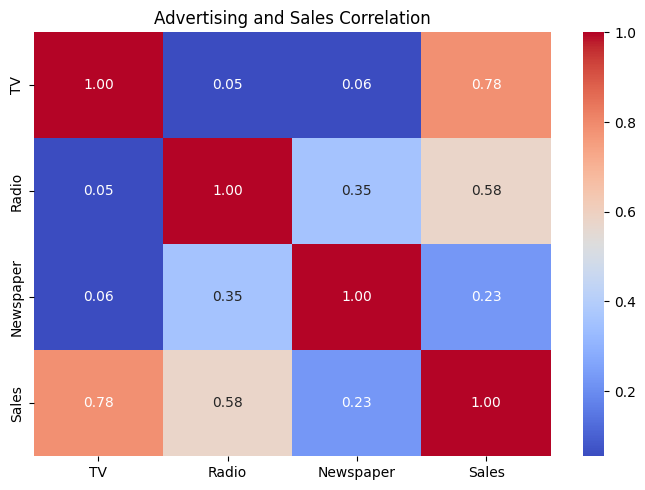

In [6]:
# 4. Explore correlation
print("\nCorrelation with Sales:")
print(df.corr()["Sales"].sort_values(ascending=False))

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Advertising and Sales Correlation")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

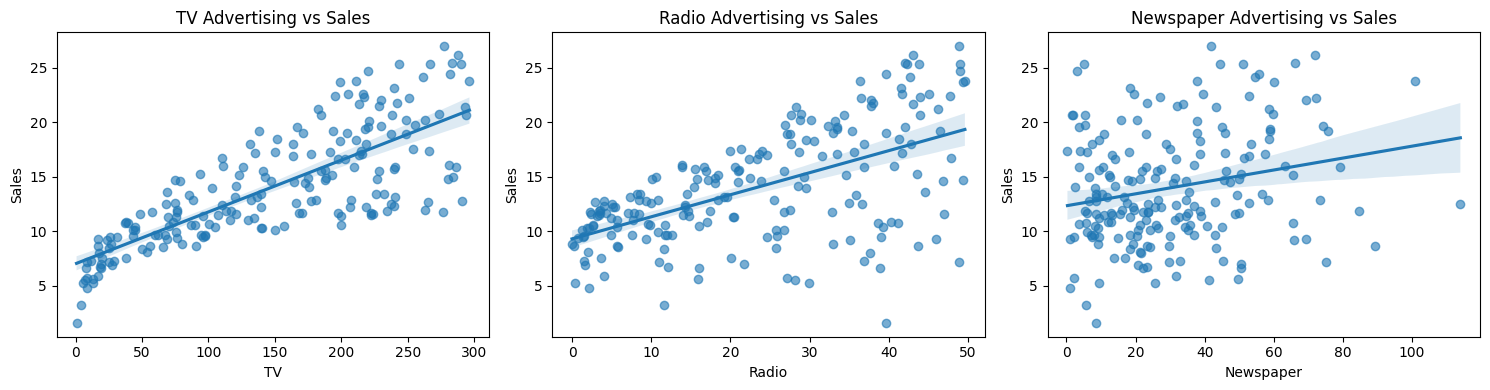

In [7]:
# 5. Visualize advertising impact
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.regplot(
        data=df,
        x=column,
        y="Sales",
        ax=ax,
        scatter_kws={"alpha": 0.6}
    )
    ax.set_title(f"{column} Advertising vs Sales")

plt.tight_layout()
plt.savefig("advertising_impact.png", dpi=300)
plt.show()

In [8]:
# 6. Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

In [10]:
# 7. Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

In [11]:
# 8. Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [12]:
# 9. Model evaluation
def evaluate_model(name, actual, predicted):
    print(f"\n{name} Performance")
    print("MAE:", round(mean_absolute_error(actual, predicted), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 3))
    print("R2 Score:", round(r2_score(actual, predicted), 4))

evaluate_model("Linear Regression", y_test, linear_predictions)
evaluate_model("Random Forest", y_test, rf_predictions)


Linear Regression Performance
MAE: 1.461
RMSE: 1.782
R2 Score: 0.8994

Random Forest Performance
MAE: 0.629
RMSE: 0.757
R2 Score: 0.9818


In [13]:
# 10. Compare model performance
results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions
})

print("\nPrediction Comparison:")
print(results.head(10).round(2))


Prediction Comparison:
   Actual Sales  Linear Regression  Random Forest
0          16.9              16.41          17.76
1          22.4              20.89          21.67
2          21.4              21.55          20.66
3           7.3              10.61           6.74
4          24.7              22.11          23.10
5          12.6              13.11          13.52
6          22.3              21.06          22.49
7           8.4               7.46           9.66
8          11.5              13.61          11.85
9          14.9              15.16          15.50



Advertising Feature Importance:
TV           0.625
Radio        0.362
Newspaper    0.013
dtype: float64


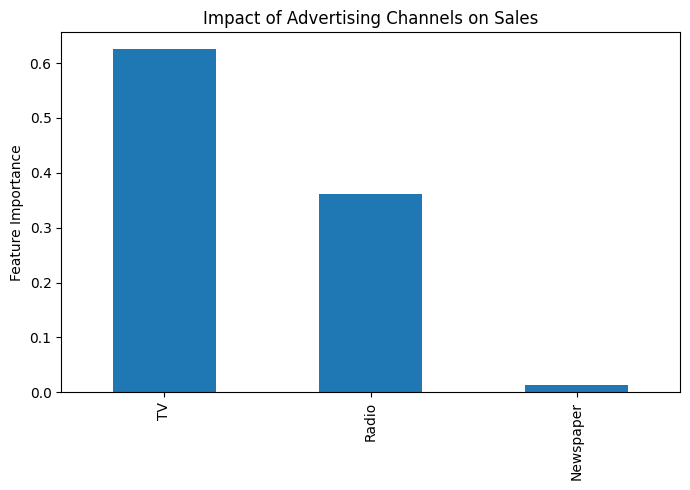

In [14]:
# 11. Feature importance
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nAdvertising Feature Importance:")
print(importance.round(3))

importance.plot(kind="bar", figsize=(7, 5))
plt.title("Impact of Advertising Channels on Sales")
plt.ylabel("Feature Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()


In [15]:
# 12. Predict sales for a new advertising budget
new_advertising = pd.DataFrame(
    [[200, 30, 40]],
    columns=X.columns
)

predicted_sales = rf_model.predict(new_advertising)

print("\nNew Advertising Budget:")
print(new_advertising)

print("Predicted Sales:", round(predicted_sales[0], 2))

print("\nSales Prediction Project Completed Successfully!")


New Advertising Budget:
    TV  Radio  Newspaper
0  200     30         40
Predicted Sales: 18.28

Sales Prediction Project Completed Successfully!
